# 用于手写数字识别的神经网络

前面我们实现了识别0和1的神经网络，现在我们进行扩展，识别 0-9

In [8]:
import numpy as np
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.activations import linear, relu, sigmoid
from utils import plt_softmax
import matplotlib.pyplot as plt

plt.style.use('./deeplearning.mplstyle')

import logging

logging.getLogger('tensorflow').setLevel(logging.ERROR)

tf.autograph.set_verbosity(0)
np.set_printoptions(precision=2)


## Softmax 函数

softmax 函数可以写为：

$$a_j = \frac{e^{z_j}}{ \sum_{k=0}^{N-1}{e^{z_k} }} \tag{1}$$

其中 $z = \mathbf{w} \cdot \mathbf{x} + b$，N 是输出层的特征数／类别数。

In [9]:
def my_softmax(z):
    """
    Softmax 将数值向量转换为概率分布。

    参数：
        z (ndarray (N,)): 输入数据，包含 N 个特征

    返回：
        a (ndarray (N,)): z 的 Softmax 结果
    """

    n = len(z)
    a = np.zeros(n)
    ez_sum = 0

    for i in range(n):
        ez_sum += np.exp(z[i])

    for j in range(n):
        a[j] = np.exp(z[j]) / ez_sum

    return a

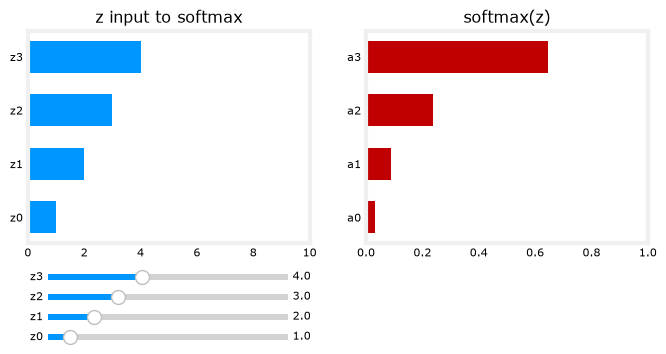

In [10]:
plt.close('all')
plt_softmax(my_softmax)

## 数据集

首先加载本任务所用的数据集
- 下面的`load_data()`函数将数据加载到变量`X`和`y`中
- 数据集包含 5000 个手写数字训练样本。
  - 每个训练样本都是一张 20 像素 × 20 像素的数字灰度图像。
    - 每个像素由一个浮点数表示，表示该位置的灰度强度。
    - 将 20 × 20 的像素网格“展开”为一个 400 维向量。
    - 每个训练样本构成数据矩阵 `X` 的一行。
    - 由此得到一个 5000 × 400 的矩阵 `X`，其中每一行都是一个手写数字图像训练样本。

$$X =
\left(\begin{array}{cc}
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\
--- (x^{(m)}) ---
\end{array}\right)$$

- 训练集的第二部分是一个 5000 × 1 的向量 `y`，其中包含训练集的标签。
  - 如果图像表示数字 `0`，则 `y = 0`；如果图像表示数字 `4`，则 `y = 4`，以此类推。

In [11]:
# 加载数据集

def load_data():
    X = np.load('X.npy')
    y = np.load('y.npy')
    return X, y


X, y = load_data()

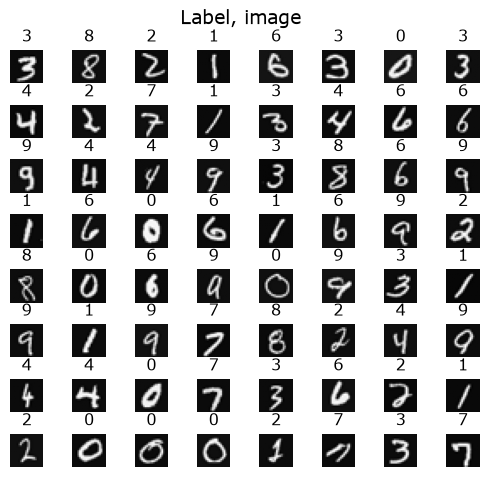

In [12]:
# 可视化数据

import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)


def widgvis(fig):
    fig.canvas.toolbar_visible = False
    fig.canvas.header_visible = False
    fig.canvas.footer_visible = False


m, n = X.shape

fig, axes = plt.subplots(8, 8, figsize=(5, 5))
fig.tight_layout(pad=0.13, rect=[0, 0.03, 1, 0.91])

widgvis(fig)

for i, ax in enumerate(axes.flat):
    random_index = np.random.randint(m)
    X_random_reshaped = X[random_index].reshape((20, 20)).T
    ax.imshow(X_random_reshaped, cmap='gray')
    ax.set_title(y[random_index, 0])
    ax.set_axis_off()
    fig.suptitle('Label, image', fontsize=14)

## 模型构建

本实验将使用如下神经网络

- 该网络包含两个使用 ReLU 激活函数的全连接层，后接一个使用线性激活函数的输出层。
  - 回顾一下，输入是数字图像的像素值。
  - 由于图像大小为 $20\times20$，因此共有 $400$ 个输入。
- 参数的维度对应于这样的神经网络：第 1 层有 $25$ 个单元，第 2 层有 $15$ 个单元，第 3 层有 $10$ 个输出单元，每个数字对应一个输出单元。
  - 回顾一下，这些参数的维度由以下规则确定：
    - 如果网络某一层有 $s_{in}$ 个单元，下一层有 $s_{out}$ 个单元，则
    - $W$ 的维度为 $s_{in} \times s_{out}$。
    - $b$ 是包含 $s_{out}$ 个元素的向量。
  - 因此，`W` 和 `b` 的形状分别为：
    - 第 1 层：`W1` 的形状为 (400, 25)，`b1` 的形状为 (25,)。
    - 第 2 层：`W2` 的形状为 (25, 15)，`b2` 的形状为 (15,)。
    - 第 3 层：`W3` 的形状为 (15, 10)，`b3` 的形状为 (10,)。


In [13]:
tf.random.set_seed(1234)

model = Sequential(
    [
        tf.keras.Input(shape=(400,)),
        Dense(25, activation='relu', name = 'L1'),
        Dense(15, activation='relu', name = 'L2'),
        Dense(10, activation='linear', name = 'L3')
    ],
    name='my_model'
)

model.summary()

Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 25)             │        10,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 15)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 10)             │           160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,575 (41.31 KB)

 Trainable params: 10,575 (41.31 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 查看权重形状

[layer1, layer2, layer3] = model.layers

W1, b1 = layer1.get_weights()
W2, b2 = layer2.get_weights()
W3, b3 = layer3.get_weights()

print(f'W1 shape = {W1.shape}, b1 shape = {b1.shape}')
print(f'W2 shape = {W2.shape}, b2 shape = {b2.shape}')
print(f'W3 shape = {W3.shape}, b3 shape = {b3.shape}')

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 10), b3 shape = (10,)


* 使用损失函数`Sparse Categorical Crossentropy`，并通过`from_logits=True`参数指定将 softmax 纳入损失计算
* 定义优化器，常用的选择是课程中介绍过的自适应矩估计(Adam)优化器

In [15]:
model.compile(
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
)

history = model.fit(X, y, epochs=100, batch_size=100)

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.9777  
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.2165
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7258
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5319
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4381 
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3804 
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3410
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3120
Epoch 9/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2891 
Epoch 10/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2705 
Epoch 11/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2549 
Epoch 12/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2415
Epoch 13/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2297 
Epoch 14/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2191
Epoch 15/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2

## 预测

下面随机抽取 64 个数字样本，比较预测结果与真实标签

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━

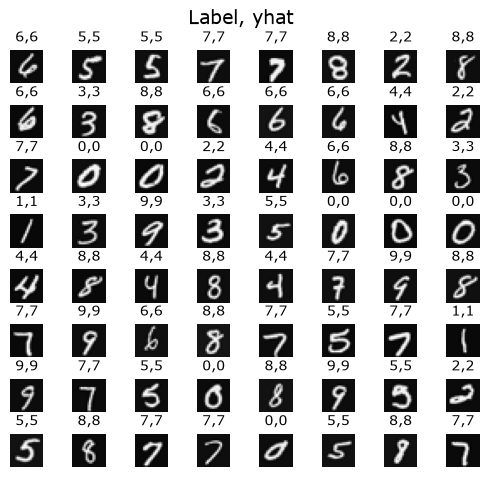

In [16]:
import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)

m, n = X.shape

fig, axes = plt.subplots(8, 8, figsize=(5, 5))
fig.tight_layout(pad=0.13, rect=[0, 0.03, 1, 0.91])
widgvis(fig)

for i, ax in enumerate(axes.flat):
    random_index = np.random.randint(m)
    X_random_reshaped = X[random_index].reshape((20, 20)).T
    ax.imshow(X_random_reshaped, cmap='gray')
    prediction = model.predict(X[random_index].reshape(1, 400))
    prediction_p = tf.nn.softmax(prediction)
    yhat = np.argmax(prediction_p)
    ax.set_title(f'{y[random_index, 0]},{yhat}', fontsize=10)
    ax.set_axis_off()

fig.suptitle('Label, yhat', fontsize=14)
plt.show()

这里查看一些错误分类的样本

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 634us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
3 errors out of 5000 images


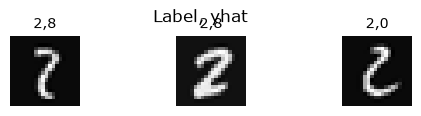

In [17]:
def display_errors(model, X, y):
    f = model.predict(X)
    yhat = np.argmax(f, axis=1)
    doo = yhat != y[:, 0]
    idxs = np.where(yhat != y[:, 0])[0]

    if len(idxs) == 0:
        print('No errors found')
    else:
        cnt = min(8, len(idxs))
        fig, ax = plt.subplots(1, cnt, figsize=(5, 1.2))
        fig.tight_layout(pad=0.13, rect=[0, 0.03, 1, 0.80])
        widgvis(fig)
        for i in range(cnt):
            j = idxs[i]
            X_reshaped = X[j].reshape((20, 20)).T
            ax[i].imshow(X_reshaped, cmap='gray')
            prediction = model.predict(X[j].reshape(1, 400))
            prediction_p = tf.nn.softmax(prediction)
            yhat = np.argmax(prediction_p)
            ax[i].set_title(f'{y[j, 0]},{yhat}', fontsize=10)
            ax[i].set_axis_off()
            fig.suptitle('Label, yhat', fontsize=12)

    return (len(idxs))


print(f'{display_errors(model, X, y)} errors out of {len(X)} images')